# Relay · Costo y acierto al elegir un modelo de lenguaje

**Aldo Santiago Márquez · Introducción a la Ciencia de Datos**

Si una consulta puede enviarse a once modelos, ¿qué se gana y qué se pierde al decidir a cuál llamar antes de ver la respuesta? El estudio considera tres preguntas. **P1** pregunta si catorce rasgos del texto permiten predecir el nivel de precio del modelo suficiente más barato. **P2** examina cuáles de esos rasgos ayudan a detectar el nivel más caro. **P3** contrasta el costo y el acierto de las rutas elegidas con los de usar un modelo fijo. Una ampliación de P3 aprende una predicción de éxito y de costo por modelo y la contrasta con una referencia de dos candidatos.

Este cuaderno reproduce el estudio de RouterBench que se presenta en el artículo. Se ejecuta con CPU, sin claves ni llamadas a modelos. El criterio principal, fijado antes de evaluar la prueba, exige reducir el costo histórico y sostener el éxito dentro de un margen de un punto porcentual frente a GPT-4. Los resultados de los modelos semánticos y de BERT que se calcularon aparte se identifican junto al código y los resúmenes que los produjeron.

[Repositorio del proyecto](https://github.com/Aldous6/Relay) · [Instrucciones y descarga de datos](../README.md) · [Protocolo original](../docs/protocolo.md) · [Protocolo final](../docs/protocolo_final.md)

## Entorno y reproducibilidad

Se usan las rutas del repositorio y la semilla 42 del protocolo. Las celdas imprimen las versiones instaladas. Para repetir los cálculos desde otra máquina se requiere el archivo de datos cuya revisión y huella se verifican en la siguiente sección. Los resultados y las gráficas de esta entrega están guardados en el propio cuaderno.

In [1]:
from pathlib import Path
from importlib.metadata import version
import json
import platform
import sys
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Permite ejecutar desde la raíz o desde notebooks/ con el mismo código.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "configs" / "final_protocol.json").is_file())
sys.path.insert(0, str(ROOT / "src"))

def read_json(path):
    """Lee un manifiesto del proyecto a partir de una ruta relativa."""
    return json.loads((ROOT / path).read_text(encoding="utf-8"))

SEED = read_json("configs/experiment.json")["seed"]
random.seed(SEED)
np.random.seed(SEED)
%matplotlib inline
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left"})

paquetes = ["numpy", "pandas", "scipy", "scikit-learn", "pyarrow", "joblib",
            "matplotlib", "matplotlib-inline", "ipykernel", "nbclient", "nbformat"]
print(f"Python {platform.python_version()} · semilla {SEED}")
display(pd.Series({nombre: version(nombre) for nombre in paquetes}, name="Versión").to_frame())

Python 3.12.10 · semilla 42


,Versión
numpy,2.3.5
pandas,2.2.3
scipy,1.17.0
scikit-learn,1.8.0
pyarrow,22.0.0
joblib,1.5.3
matplotlib,3.10.8
matplotlib-inline,0.1.7
ipykernel,6.30.1
nbclient,0.10.2


## Datos y unidad de análisis

Cada fila de RouterBench contiene una consulta y resultados históricos de once modelos para ese mismo texto. Un acierto equivale a un puntaje de al menos 0,75. Conocer los resultados de los once permite calcular qué habría ocurrido al elegir cada uno. La decisión del selector solo puede usar lo que se conocía antes de recibir la respuesta.

Se utiliza el archivo `routerbench_0shot.pkl` de la [revisión fijada por Martian](https://huggingface.co/datasets/withmartian/routerbench/tree/784021482c3f320c6619ed4b3bb3b41a21424fcb). *Zero-shot* indica que la consulta no incluye ejemplos de demostración. El archivo original ocupa 99,6 MB y se obtiene siguiendo el [README](../README.md). Aquí se reconstruyen las tablas desde ese archivo sin escribir sobre él ni depender de archivos intermedios de otra máquina.

In [2]:
from routerbench.data import hash_partition, load_verified_pickle, prompt_metadata
from routerbench.features import FEATURE_NAMES, extract_features
from routerbench.labels import fit_tiers, make_labels, outcome_tables

config_datos = read_json("configs/experiment.json")
origen = config_datos["dataset"]
ruta_datos = ROOT / origen["path"]
umbral_score = config_datos["quality_threshold"]

# El cargador verifica el SHA-256 autorizado antes de deserializar el archivo.
if not ruta_datos.is_file():
    raise FileNotFoundError(f"Descarga {origen['path']} según el README del repositorio.")
datos_originales = load_verified_pickle(ruta_datos, origen["sha256"])
assert datos_originales.shape == (origen["expected_rows"], origen["expected_columns"])

# La función valida pares modelo–costo, valores finitos, puntajes en [0, 1] y costos no negativos.
puntajes_originales, costos_originales = outcome_tables(datos_originales)
assert puntajes_originales.shape[1] == origen["expected_models"]
print(f"{len(datos_originales):,} filas · {datos_originales.shape[1]} columnas · "
      f"{puntajes_originales.shape[1]} modelos · {datos_originales['eval_name'].nunique()} evaluaciones")
print(f"SHA-256 verificado: {origen['sha256']}")
print("Puntajes y costos ausentes:", puntajes_originales.isna().sum().sum(),
      "y", costos_originales.isna().sum().sum())

36,497 filas · 37 columnas · 11 modelos · 86 evaluaciones
SHA-256 verificado: ba4f77f19517610a707c374e99322d7750c30fc4ae7ff5527888595a1e65d36d
Puntajes y costos ausentes: 0 y 0


## Preprocesamiento y separación de consultas

Una consulta repetida en ambos conjuntos permitiría reconocerla al evaluar el modelo. Se reconstruyen los turnos del texto y se usa una copia normalizada (Unicode NFKC, minúsculas mediante `casefold` y espacios colapsados) para obtener su huella SHA-256. En cada grupo se conserva la primera aparición por orden del archivo. Así, dos filas duplicadas con puntajes distintos reciben el mismo tratamiento que dos con puntajes idénticos. La partición usa únicamente la huella y la semilla, con probabilidad de prueba de 0,20. El texto para modelado conserva mayúsculas, saltos de línea e indentación.

In [3]:
metadatos = prompt_metadata(datos_originales)
filas_repetidas = metadatos["prompt_group"].duplicated(keep="first")
rows = metadatos.loc[~filas_repetidas].reset_index(drop=True).copy()
rows["split"] = hash_partition(
    rows["prompt_group"], config_datos["seed"], config_datos["split"]["test_fraction"]
)
train_mask = rows["split"].eq("train")
test_mask = rows["split"].eq("test")
grupos_train = set(rows.loc[train_mask, "prompt_group"])
grupos_test = set(rows.loc[test_mask, "prompt_group"])
assert rows["prompt_group"].is_unique and grupos_train.isdisjoint(grupos_test)
assert (train_mask ^ test_mask).all()

# El orden posicional del original vincula cada consulta con los once resultados correctos.
posiciones = rows["source_row"].to_numpy()
datos_unicos = datos_originales.iloc[posiciones].reset_index(drop=True)
scores = puntajes_originales.iloc[posiciones].reset_index(drop=True)
costs = costos_originales.iloc[posiciones].reset_index(drop=True)
print(f"Filas duplicadas retiradas: {filas_repetidas.sum()} · consultas únicas: {len(rows):,}")
print(f"Entrenamiento: {train_mask.sum():,} · prueba: {test_mask.sum():,} · "
      f"huellas compartidas: {len(grupos_train & grupos_test)}")

Filas duplicadas retiradas: 16 · consultas únicas: 36,481
Entrenamiento: 29,157 · prueba: 7,324 · huellas compartidas: 0


**Dos usos de los resultados históricos.** Para predecir el nivel, el precio típico de un modelo se estima por su mediana en el entrenamiento exterior. Se ordenan los once modelos y se asignan dos al nivel económico, seis al intermedio y tres al premium. Cada consulta hereda el nivel del modelo que alcanzó el puntaje exigido al menor costo en esa fila. Un empate de costo se resuelve por nombre. Si todos fallaron, la consulta queda sin nivel. Para evaluar una política de selección, esa misma consulta sí cuenta en el costo y en el denominador del éxito porque también habría requerido una llamada.

In [4]:
# El mapa de precios se ajusta después de separar los grupos y solo con entrenamiento.
tier_map = fit_tiers(datos_unicos.loc[train_mask], config_datos["tier_sizes"])
labels = make_labels(datos_unicos, tier_map, threshold=umbral_score)
X_estructura = extract_features(rows["prompt_text"])
assert list(X_estructura.columns) == list(FEATURE_NAMES)
assert X_estructura.index.equals(labels.index) and labels.index.equals(rows.index)
assert np.isfinite(X_estructura.to_numpy()).all()
assert labels["tier"].isna().equals(~labels["eligible"])
assert tier_map == read_json("reports/final-tiers/summary.json")["tier_map"]

poblaciones = rows.groupby("split").size().rename("Todas").to_frame()
poblaciones["Con nivel"] = labels["eligible"].groupby(rows["split"]).sum()
poblaciones["Sin modelo que acierte"] = poblaciones["Todas"] - poblaciones["Con nivel"]
display(poblaciones.loc[["train", "test"]].rename(index={"train": "Entrenamiento", "test": "Prueba"}))
print("Predictores permitidos (14):", ", ".join(X_estructura.columns))

,Todas,Con nivel,Sin modelo que acierte
split,,,
Entrenamiento,29157,27964,1193
Prueba,7324,7013,311


Predictores permitidos (14): n_chars, n_words, n_lines, avg_word_length, lexical_diversity, digit_ratio, punctuation_ratio, uppercase_ratio, n_questions, n_brackets, n_code_markers, n_math_symbols, non_ascii_ratio, cjk_ratio


## Exploración que orienta el modelado

¿Bastaría la longitud para identificar las consultas premium? ¿Qué perderíamos si solo midiéramos exactitud global? Se cruzan las etiquetas elegibles de **entrenamiento** con los conteos de caracteres. El gráfico izquierdo muestra la frecuencia de cada clase. El derecho resume la longitud con la mediana y el rango entre el primer y el tercer cuartil. Ese rango cubre la mitad central de las consultas de cada nivel. Las consultas de prueba permanecen fuera de esta exploración.

,Consultas,Proporción (%),P25,Mediana,P75
nivel,,,,,
Económico,14805,52.94,342.0,578.0,1084.0
Intermedio,12033,43.03,440.0,969.0,1132.0
Premium,1126,4.03,398.0,546.0,1115.0


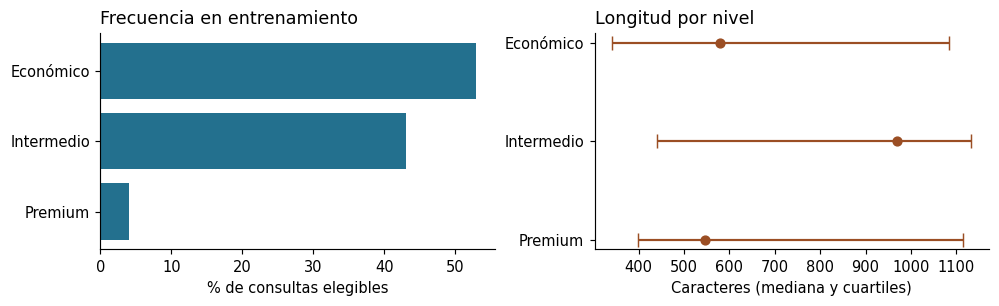

In [5]:
nombres_nivel = {0: "Económico", 1: "Intermedio", 2: "Premium"}
eda_train = X_estructura.loc[train_mask & labels["eligible"], ["n_chars"]].copy()
eda_train["nivel"] = labels.loc[eda_train.index, "tier"].map(nombres_nivel)
por_nivel = eda_train.groupby("nivel")["n_chars"]
resumen_eda = por_nivel.quantile([0.25, 0.50, 0.75]).unstack()
resumen_eda.columns = ["P25", "Mediana", "P75"]
resumen_eda["Consultas"] = por_nivel.size()
resumen_eda["Proporción (%)"] = 100 * resumen_eda["Consultas"] / len(eda_train)
resumen_eda = resumen_eda.loc[list(nombres_nivel.values())]
display(resumen_eda[["Consultas", "Proporción (%)", "P25", "Mediana", "P75"]].round(2))

fig, (frecuencia, longitud) = plt.subplots(1, 2, figsize=(9.4, 2.8), layout="constrained")
pos_niveles = np.arange(len(resumen_eda))
frecuencia.barh(pos_niveles, resumen_eda["Proporción (%)"], color="#23708e")
frecuencia.set(yticks=pos_niveles, yticklabels=resumen_eda.index,
               xlabel="% de consultas elegibles", title="Frecuencia en entrenamiento")
medianas = resumen_eda["Mediana"]
distancias = np.vstack([medianas - resumen_eda["P25"], resumen_eda["P75"] - medianas])
longitud.errorbar(medianas, pos_niveles, xerr=distancias, fmt="o", capsize=5, color="#9b4e24")
longitud.set(yticks=pos_niveles, yticklabels=resumen_eda.index,
             xlabel="Caracteres (mediana y cuartiles)", title="Longitud por nivel")
for eje in (frecuencia, longitud):
    eje.invert_yaxis()
    eje.spines[["top", "right"]].set_visible(False)
plt.show()

En entrenamiento, el nivel premium representa solo el 4,03 % de las consultas con etiqueta. Predecir siempre la clase mayoritaria permite acertar el 52,94 % sin detectar una sola premium. Esto justifica comparar contra esa línea base y dar el mismo peso a cada clase con F1 macro, junto con la sensibilidad premium. La longitud mediana fue de 578 caracteres en el nivel económico, 969 en el intermedio y 546 en el premium. Los tres rangos centrales se superponen. Por eso se incluye una línea base que solo ve la longitud y se contrasta con predictores que ven más atributos. Estos grupos describen el catálogo histórico y su criterio de éxito. El tamaño del texto, por sí solo, deja consultas de distintos niveles en rangos similares.

## ¿Puede la estructura de la consulta predecir su nivel de costo?

**P1.** La etiqueta indica el nivel del modelo suficiente más barato observado. La clase mayoritaria y un árbol de profundidad dos que solo usa el número de caracteres establecen qué se puede conseguir con poca información. Comparamos también una regresión logística con escalado robusto y pesos balanceados, y un bosque de 300 árboles con balanceo por submuestra. Cada modelo ve las mismas consultas elegibles y las mismas cinco particiones estratificadas de entrenamiento. El F1 de cada nivel combina precisión y sensibilidad. Seleccionamos el mayor F1 macro medio para que los tres niveles tengan el mismo peso, aunque el premium sea poco frecuente. El escalado y el ajuste se repiten dentro de cada partición.

In [6]:
from sklearn.base import clone
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from routerbench.models import build_models

config_niveles = read_json("configs/experiment.json")
semilla_niveles = config_niveles["seed"]
modelos_nivel = build_models(seed=semilla_niveles)
nombres_nivel = {
    "dummy": "Mayoría", "length": "Longitud",
    "logistic": "Regresión logística", "random_forest": "Bosque aleatorio",
}
elegibles_train = train_mask & labels["eligible"]
X_niv_train = X_estructura.loc[elegibles_train]
y_niv_train = labels.loc[elegibles_train, "tier"].astype(int)

# Fijar las mismas filas en cada fold mantiene la comparación pareada entre métodos.
partidor = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla_niveles)
folds_nivel = list(partidor.split(X_niv_train, y_niv_train))
medir_f1 = make_scorer(f1_score, average="macro", labels=[0, 1, 2], zero_division=0)
f1_nivel = pd.DataFrame({
    nombre: cross_val_score(modelo, X_niv_train, y_niv_train,
                            scoring=medir_f1, cv=folds_nivel, error_score="raise")
    for nombre, modelo in modelos_nivel.items()
})
cv_nivel = f1_nivel.agg(["mean", "std"]).T
ganador_nivel = sorted(cv_nivel.index, key=lambda m: (-cv_nivel.at[m, "mean"], m))[0]

# Consultar solo el registro de selección producido con entrenamiento.
registro_seleccion = read_json("reports/final-tiers/selection.json")
assert registro_seleccion["outer_test_metrics_used"] is False
assert ganador_nivel == registro_seleccion["selected_model"]
for nombre in modelos_nivel:
    esperado = registro_seleccion["cv_summary"][nombre]
    np.testing.assert_allclose(cv_nivel.loc[nombre], [
        esperado["metrics_mean"]["f1_macro"], esperado["metrics_std"]["f1_macro"]
    ])
display(cv_nivel.rename(index=nombres_nivel, columns={"mean": "F1 macro medio", "std": "DE entre folds"}).round(4))
print(f"Selección antes de prueba: {nombres_nivel[ganador_nivel]} en {len(y_niv_train):,} consultas elegibles.")

,F1 macro medio,DE entre folds
Mayoría,0.2308,0.0000
Longitud,0.3860,0.0050
Regresión logística,0.3892,0.0089
Bosque aleatorio,0.4464,0.0110


Selección antes de prueba: Bosque aleatorio en 27,964 consultas elegibles.


**P2. ¿Qué rasgos ayudan al bosque a reconocer el nivel premium?** Volvemos a ajustar el modelo seleccionado en tres particiones de entrenamiento. En las filas de validación de cada partición mezclamos una variable entre consultas, mantenemos las demás intactas y medimos la caída del F1 premium. Cada mezcla se repite cinco veces. La desviación estándar resume esas 15 caídas y la última columna cuenta en cuántas de las tres particiones la variable quedó entre las tres primeras. La función de cálculo es la del experimento original en [tier_experiment.py](../src/routerbench/tier_experiment.py).

In [7]:
from routerbench.tier_experiment import _permutation_on_training

importancia_nivel, _, diseno_permutacion = _permutation_on_training(
    modelos_nivel[ganador_nivel], X_niv_train, y_niv_train, seed=semilla_niveles, repeats=5
)
tabla_perm = importancia_nivel.set_index("feature")[[
    "mean_f1_tier2_drop", "std_f1_tier2_drop", "top3_fold_fraction"
]].copy()
tabla_perm["top3_fold_fraction"] = (tabla_perm["top3_fold_fraction"] * diseno_permutacion["folds"]).round().astype(int)
tabla_perm.columns = ["Caída media de F1 premium", "DE de las caídas", "Particiones en top 3 (de 3)"]
display(tabla_perm.round(4))

,Caída media de F1 premium,DE de las caídas,Particiones en top 3 (de 3)
feature,,,
uppercase_ratio,0.0639,0.0219,3
n_words,0.0262,0.0216,3
n_code_markers,0.0123,0.0135,1
n_chars,0.0119,0.0094,0
digit_ratio,0.0079,0.0125,0
non_ascii_ratio,0.0065,0.0060,1
n_brackets,0.0064,0.0064,0
punctuation_ratio,0.0048,0.0029,1
cjk_ratio,0.0028,0.0034,0


La mayor caída media correspondió a la proporción de mayúsculas, seguida del número de palabras. Ambas estuvieron entre las tres primeras en las tres particiones. Las marcas de código entraron una sola vez. La permutación describe señales que el bosque aprovechó. Podrían reflejar los formatos de los benchmarks y cambiar de importancia si cambia la mezcla de tareas.

**Prueba reservada y análisis de errores.** Con el ganador ya fijado, reajustamos los cuatro modelos en todas las consultas elegibles de entrenamiento. Predecimos el nivel de todas las consultas de prueba para disponer de una ruta incluso si ningún modelo acierta. Solo las filas con nivel verdadero definido entran en la evaluación de clasificación. La matriz muestra el conteo y, entre paréntesis, el porcentaje dentro de cada nivel real.

,F1 macro,Exactitud balanceada,Sensibilidad premium,F1 premium
Mayoría,0.2323,0.3333,0.0000,0.0000
Longitud,0.3831,0.4132,0.2469,0.1174
Regresión logística,0.3954,0.4770,0.5125,0.1417
Bosque aleatorio,0.4445,0.4359,0.0906,0.1371


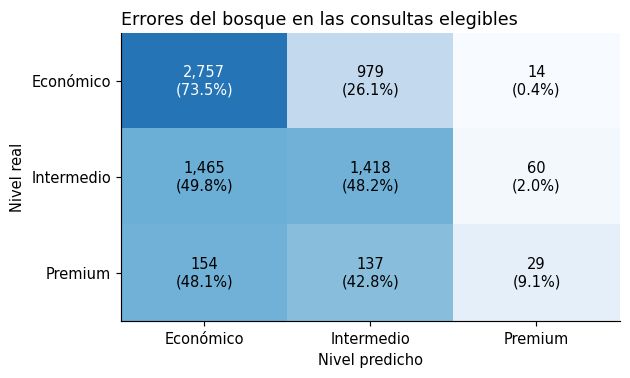

In [8]:
from routerbench.tier_experiment import classification_metrics

pred_niv_prueba = pd.DataFrame(index=X_estructura.index[test_mask])
for nombre, modelo in modelos_nivel.items():
    ajustado = clone(modelo).fit(X_niv_train, y_niv_train)
    pred_niv_prueba[nombre] = ajustado.predict(X_estructura.loc[test_mask])

elegibles_prueba = labels.index[test_mask & labels["eligible"]]
y_niv_prueba = labels.loc[elegibles_prueba, "tier"].astype(int)
resultados_nivel = {
    nombre: classification_metrics(y_niv_prueba, pred_niv_prueba.loc[elegibles_prueba, nombre])
    for nombre in modelos_nivel
}
resumen_niveles = read_json("reports/final-tiers/summary.json")
assert resumen_niveles["permutation_importance"]["top_three"] == diseno_permutacion["top_three"]
for nombre, metrica in resultados_nivel.items():
    np.testing.assert_array_equal(metrica["confusion_matrix"], resumen_niveles["test"][nombre]["confusion_matrix"])
tabla_prueba = pd.DataFrame(resultados_nivel).T[["f1_macro", "balanced_accuracy", "tier2_recall", "tier2_f1"]].astype(float)
tabla_prueba.columns = ["F1 macro", "Exactitud balanceada", "Sensibilidad premium", "F1 premium"]
display(tabla_prueba.rename(index=nombres_nivel).round(4))

conteos = np.array(resultados_nivel[ganador_nivel]["confusion_matrix"])
fraccion = conteos / conteos.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.1, 3.7))
ax.imshow(fraccion, vmin=0, vmax=1, cmap="Blues", aspect="auto")
niveles = ["Económico", "Intermedio", "Premium"]
ax.set(xticks=range(3), xticklabels=niveles, yticks=range(3), yticklabels=niveles,
       xlabel="Nivel predicho", ylabel="Nivel real", title="Errores del bosque en las consultas elegibles")
for (fila, columna), cantidad in np.ndenumerate(conteos):
    ax.text(columna, fila, f"{cantidad:,}\n({fraccion[fila, columna]:.1%})", ha="center", va="center",
            color="white" if fraccion[fila, columna] > 0.55 else "black")
fig.tight_layout()
plt.show()

El bosque obtuvo el mejor F1 macro durante la selección y llegó a 0,4445 en prueba, frente a 0,3831 usando solo longitud. Sin embargo, reconoció 29 de los 320 casos premium. Clasificó otros 154 como económicos y 137 como intermedios. La logística detectó 164 de 320. Si el costo principal de un error fuera enviar una consulta premium a un nivel inferior, convendría fijar esa prioridad en desarrollo y evaluarla en una muestra nueva.

## ¿Qué sucede al seguir la recomendación de nivel?

**P3.** Para transformar un nivel en una llamada elegimos un representante por nivel según la mayor tasa de éxito en todo el entrenamiento. En caso de empate se prefiere el menor costo medio y después el nombre. Se fijan así las dos decisiones necesarias, el clasificador y el representante, antes de consultar el éxito o el costo de las rutas de prueba. La unidad de evaluación vuelve a ser cada una de las 7.324 consultas, incluidas las 311 sin nivel asignable.

In [9]:
from routerbench.tier_policy import route_predicted_tiers, select_representatives

eleccion_reps = select_representatives(scores.loc[train_mask], costs.loc[train_mask], tier_map)
representantes_nivel = eleccion_reps["representatives"]
rutas_nivel = route_predicted_tiers(pred_niv_prueba[ganador_nivel], representantes_nivel)
referencia_nivel = pd.Series(representantes_nivel[2], index=rutas_nivel.index, dtype="string")
tabla_reps = pd.DataFrame({
    "Nivel": niveles, "Representante elegido en entrenamiento": list(representantes_nivel.values()),
    "Consultas asignadas": [int(rutas_nivel.eq(representantes_nivel[t]).sum()) for t in range(3)],
})
display(tabla_reps.set_index("Nivel"))

,Representante elegido en entrenamiento,Consultas asignadas
Nivel,,
Económico,WizardLM/WizardLM-13B-V1.2,4516
Intermedio,zero-one-ai/Yi-34B-Chat,2670
Premium,gpt-4-1106-preview,138


In [10]:
from routerbench.comparison import paired_bootstrap
from routerbench.policy import evaluate_policy

# Obtener el puntaje y el costo de una sola llamada por consulta después de elegir cada ruta.
test_scores, test_costs = scores.loc[test_mask], costs.loc[test_mask]
por_nivel = evaluate_policy(rutas_nivel, test_scores, test_costs, umbral_score)
premium_fijo = evaluate_policy(referencia_nivel, test_scores, test_costs, umbral_score)
contraste_nivel = paired_bootstrap(por_nivel["rows"], premium_fijo["rows"], replicates=5000, seed=semilla_niveles)
informe_p3 = read_json("reports/final-tier-policy-v1/summary.json")
assert representantes_nivel == {int(t): m for t, m in informe_p3["representative_selection"]["representatives"].items()}
for medida in ("success_rate_delta", "relative_call_cost_saving"):
    for sufijo in ("", "_95ci"):
        clave = medida + sufijo
        np.testing.assert_allclose(contraste_nivel[clave], informe_p3["comparison_vs_premium"][clave])

tabla_p3 = pd.DataFrame({"Por nivel": por_nivel["metrics"], "GPT-4 fijo": premium_fijo["metrics"]}).T
tabla_p3 = tabla_p3[["n_prompts", "n_successes", "success_rate", "cost_per_1000"]].astype(float)
tabla_p3["success_rate"] *= 100
tabla_p3.columns = ["Consultas", "Aciertos", "Éxito (%)", "USD históricos por mil"]
tabla_p3[["Consultas", "Aciertos"]] = tabla_p3[["Consultas", "Aciertos"]].astype(int)
display(tabla_p3.round(4))
for medida, etiqueta in [("success_rate_delta", "Diferencia de éxito (pp)"),
                         ("relative_call_cost_saving", "Ahorro histórico (%)")]:
    inferior, superior = np.array(contraste_nivel[medida + "_95ci"]) * 100
    print(f"{etiqueta}: {100 * contraste_nivel[medida]:.2f} (IC del 95 %: {inferior:.2f} a {superior:.2f}).")

# Cruzar nivel correcto y respuesta correcta separa dos tipos distintos de acierto.
nivel_correcto = pred_niv_prueba.loc[elegibles_prueba, ganador_nivel].eq(y_niv_prueba)
respuesta_correcta = por_nivel["rows"].loc[elegibles_prueba, "success"]
cruce_errores = pd.crosstab(
    nivel_correcto.map({False: "Nivel equivocado", True: "Nivel correcto"}),
    respuesta_correcta.map({False: "Respuesta insuficiente", True: "Respuesta suficiente"}),
)
display(cruce_errores.rename_axis(index="Consultas elegibles", columns="Puntaje del representante"))

,Consultas,Aciertos,Éxito (%),USD históricos por mil
Por nivel,7324,4033,55.0655,0.1621
GPT-4 fijo,7324,5758,78.6182,3.2293


Diferencia de éxito (pp): -23.55 (IC del 95 %: -24.82 a -22.28).
Ahorro histórico (%): 94.98 (IC del 95 %: 94.50 a 95.37).


Puntaje del representante,Respuesta insuficiente,Respuesta suficiente
Consultas elegibles,,
Nivel correcto,971,3233
Nivel equivocado,2009,800


La política por niveles ahorró el 94,98 % del costo histórico, pero pasó del 78,62 % al 55,07 % de éxito. El cruce de errores explica una parte de esta caída: aun con el nivel correcto, el representante puede fallar. La etiqueta se construyó porque *algún* modelo del nivel alcanzó el puntaje requerido. Elegir un único representante pierde la diferencia entre modelos que pertenecen al mismo nivel. Esta observación motiva estimar el éxito y el costo de cada modelo por separado.

## Selección directa entre once modelos

Predecir el nivel y después usar un único representante tiene un costo: puede acertar otro modelo del mismo grupo. Por eso ampliamos P3. Para cada consulta aprendemos once indicadores de éxito y estimamos cuánto costaría cada llamada. Se incluyen las consultas en las que fallaron los once. El ajuste y la calibración reciben conjuntos distintos del entrenamiento exterior; la validación de desarrollo decide qué política se congela. Se conserva el tope de 6.000 consultas de ajuste del piloto para reproducir el estudio del artículo.

La versión principal combina los catorce rasgos con TF–IDF de palabras (uno y dos términos) y de caracteres (tres a cinco dentro de palabra). Cada vocabulario retiene hasta 20.000 términos presentes en al menos dos documentos de ajuste. Una regresión logística por modelo estima el acierto, con calibración sigmoide en su propio conjunto. Una regresión ridge usa los conteos de caracteres, palabras y líneas para predecir el logaritmo del costo, con corrección al convertirlo de vuelta a dólares. El vocabulario y los parámetros de los predictores se aprenden únicamente en ajuste. [Implementación de entrenamiento](../src/routerbench/learner.py) · [Representaciones](../src/routerbench/representations.py)

In [11]:
from routerbench.development import development_partition
from routerbench.learner import SuccessCostRouter
from routerbench.policy import choose_models, evaluate_policy

directa = read_json("configs/competitor.json")
protocolo = read_json("configs/final_protocol.json")
piloto = read_json("reports/competitor-development-pilot-v1/summary.json")
entrada_directa = pd.concat([rows["prompt_text"], X_estructura], axis=1)
assert list(entrada_directa) == ["prompt_text", *FEATURE_NAMES]

grupos = rows.loc[train_mask, "prompt_group"]
bloques = development_partition(grupos, SEED)
# El piloto original tomó las primeras 6.000 huellas ordenadas de la porción de ajuste.
ajuste = grupos[bloques.eq("fit")].sort_values().index[:piloto["pilot_max_fit_rows"]]
calibracion = bloques[bloques.eq("calibration")].index
validacion = bloques[bloques.eq("validation")].index
prueba = rows.index[test_mask]
roles = bloques.copy()
roles.loc[bloques.eq("fit") & ~bloques.index.isin(ajuste)] = "unused_fit_pilot"
assert roles.value_counts().to_dict() == piloto["partition_counts"]
assert grupos.is_unique and bloques.index.intersection(prueba).empty

# La referencia fija se decide entre los once usando exclusivamente el ajuste.
tasa_ajuste = scores.loc[ajuste].ge(umbral_score).mean()
gasto_ajuste = costs.loc[ajuste].mean()
fijo = min(scores.columns, key=lambda m: (-tasa_ajuste[m], gasto_ajuste[m], m))
assert fijo == protocolo["reference"]["fixed_model"]
display(roles.value_counts().rename(index={"fit":"Ajuste usado", "calibration":"Calibración",
    "validation":"Validación", "unused_fit_pilot":"Ajuste disponible sin usar"}).to_frame("Consultas"))
print("Referencia fija seleccionada en ajuste:", fijo)

,Consultas
prompt_group,
Ajuste disponible sin usar,14368
Ajuste usado,6000
Validación,4406
Calibración,4383


Referencia fija seleccionada en ajuste: gpt-4-1106-preview


In [12]:
# Se reproducen en CPU las dos variantes sin encoder con idénticas filas y semilla.
selectores = {}
for variante, representacion in [("lexical_hybrid", "hybrid"), ("structural", "structural")]:
    selector = SuccessCostRouter(
        representation=representacion, seed=SEED, quality_threshold=umbral_score,
        max_features=directa["lexical"]["max_features_per_block"], min_df=directa["lexical"]["min_df"]
    )
    selector.fit(entrada_directa.loc[ajuste], scores.loc[ajuste], costs.loc[ajuste],
                 entrada_directa.loc[calibracion], scores.loc[calibracion])
    selectores[variante] = selector
    print(f"{variante}: {len(selector.models_)} modelos · {selector.fit_rows_} en ajuste · "
          f"{selector.calibration_rows_} en calibración · {selector.transformer_.n_features_out_} variables")

lexical_hybrid: 11 modelos · 6000 en ajuste · 4383 en calibración · 40014 variables


structural: 11 modelos · 6000 en ajuste · 4383 en calibración · 14 variables


### De la probabilidad a una decisión

Para cada consulta se elige el menor costo previsto entre los modelos que alcanzan una probabilidad mínima. Si ninguno llega, se usa el de mayor probabilidad y se desempata por costo y luego por nombre. El **0,75 del puntaje de RouterBench** define si la respuesta acertó. La **probabilidad mínima del selector** es una decisión que se escogió en validación.

La política principal se fijó con las curvas de cuatro representaciones y ocho umbrales. Recalculamos las dos curvas anteriores y cargamos las dos del encoder desde su [ejecución externa](../reports/relay-semantic-development-v1/summary.json). El criterio elige el costo más bajo entre las combinaciones cuya tasa de acierto de validación alcanza la del fijo menos un punto porcentual. El test no interviene en esta búsqueda.

In [13]:
curvas = []
for variante, selector in selectores.items():
    prob, costo_previsto = selector.predict_tables(entrada_directa.loc[validacion])
    for umbral in directa["policy"]["probability_threshold_grid"]:
        ruta = choose_models(prob, costo_previsto, umbral)
        observado = evaluate_policy(ruta["selected_model"], scores.loc[validacion],
                                   costs.loc[validacion], umbral_score)["metrics"]
        curvas.append((variante, umbral, observado["success_rate"], observado["cost_per_1000"]))

semantico = read_json("reports/relay-semantic-development-v1/summary.json")
assert semantico["partition_counts"] == piloto["partition_counts"]
for variante, registro in semantico["variants"].items():
    for punto in registro["development_cost_quality_curve"]:
        curvas.append((variante, punto["minimum_predicted_success"],
                       punto["success_rate"], punto["cost_per_1000"]))

tabla_curvas = pd.DataFrame(curvas, columns=["Variante", "Umbral", "Éxito", "USD por mil"])
piso = scores.loc[validacion, fijo].ge(umbral_score).mean() - protocolo["selection"]["quality_loss_margin"]
factibles = tabla_curvas[tabla_curvas["Éxito"].ge(piso)].sort_values(
    ["USD por mil", "Éxito", "Variante", "Umbral"], ascending=[True, False, True, True])
elegida = factibles.iloc[0]
assert len(tabla_curvas) == 32 and elegida["Variante"] == protocolo["selection"]["chosen_variant"]
assert np.isclose(elegida["Umbral"], protocolo["selection"]["chosen_probability_threshold"])
# Mostrar el punto más económico admisible de cada representación facilita la comparación.
print(f"Piso de éxito en validación: {piso:.2%}. Política congelada: {elegida['Variante']}.")
display(factibles.drop_duplicates("Variante").set_index("Variante").round(5))

Piso de éxito en validación: 77.69%. Política congelada: lexical_hybrid.


,Umbral,Éxito,USD por mil
Variante,,,
lexical_hybrid,0.75,0.78234,1.79272
semantic_hybrid,0.75,0.78393,1.88096
semantic,0.75,0.78961,1.91531
structural,0.75,0.79233,2.18888


### Una decisión antes de ver el resultado

Se toma la primera consulta de prueba en el orden de la partición, sin buscar una ilustración favorable. La tabla muestra los once candidatos, sus estimaciones y la ruta. Para decidir solo entran las características de la consulta y las estimaciones aprendidas. Los puntajes y costos históricos se consultan en la celda de evaluación posterior.

In [14]:
prob_prueba, costo_prueba = selectores[elegida["Variante"]].predict_tables(entrada_directa.loc[prueba])
ruta_primaria = choose_models(prob_prueba, costo_prueba, elegida["Umbral"])
indice = prueba[0]
ejemplo = pd.DataFrame({"P estimada de acierto": prob_prueba.loc[indice],
                        "USD previstos": costo_prueba.loc[indice]})
ejemplo["Alcanza el umbral"] = ejemplo["P estimada de acierto"].ge(elegida["Umbral"])
ejemplo["Elegido"] = ejemplo.index == ruta_primaria.loc[indice, "selected_model"]
display(ejemplo.sort_values("USD previstos").round(6))
print(f"Regla aplicada: {ruta_primaria.loc[indice, 'decision']}.")
print(f"En toda la prueba fue necesario el respaldo en {ruta_primaria['decision'].eq('fallback').mean():.2%} de las consultas.")

,P estimada de acierto,USD previstos,Alcanza el umbral,Elegido
mistralai/mistral-7b-chat,0.105110,0.000006,False,False
WizardLM/WizardLM-13B-V1.2,0.100696,0.000009,False,False
mistralai/mixtral-8x7b-chat,0.121555,0.000020,False,False
meta/code-llama-instruct-34b-chat,0.040291,0.000023,False,False
claude-instant-v1,0.092218,0.000025,False,False
zero-one-ai/Yi-34B-Chat,0.107657,0.000025,False,False
gpt-3.5-turbo-1106,0.168000,0.000029,False,False
meta/llama-2-70b-chat,0.042668,0.000031,False,False
claude-v1,0.177901,0.000267,False,False
claude-v2,0.202612,0.000311,False,True


Regla aplicada: fallback.
En toda la prueba fue necesario el respaldo en 23.36% de las consultas.


## Evaluación sobre las mismas 7.324 consultas

Para cada ruta se recuperan el puntaje y el costo de la respuesta del modelo elegido. El denominador es común e incluye las 311 consultas que ningún candidato resolvió. Se reproduce también la política binaria de Relay, restringiendo las columnas a GPT-4 y Mixtral y aplicando el umbral seleccionado por separado en desarrollo. El BERT publicado por RouteLLM se evaluó con un [adaptador local de inferencia](../src/routerbench/routellm_reference.py) para el mismo par. Sus pesos se entrenaron externamente y se cargan aquí sus [resultados registrados](../reports/routellm-bert-secondary-v1/summary.json). Esta referencia secundaria evalúa transferencia; no es la variante MF de RouteLLM.

In [15]:
final = read_json("reports/final/summary.json")
informe_par = read_json("reports/routellm-bert-secondary-v1/summary.json")
config_par = read_json("configs/routellm_reference.json")
candidatos_par = [config_par["common_pair"]["strong"], config_par["common_pair"]["weak"]]
assert not final["policy_selection_used_test"] and not informe_par["test_outcomes_used_for_selection"]

prob_est, costo_est = selectores["structural"].predict_tables(entrada_directa.loc[prueba])
rutas_est = choose_models(prob_est, costo_est, protocolo["policies"][1]["minimum_predicted_success"])
umbral_par = informe_par["selected"]["relay_common_pair"]["threshold"]
rutas_par = choose_models(prob_prueba[candidatos_par], costo_prueba[candidatos_par], umbral_par)

def evaluar_ruta(ruta):
    return evaluate_policy(ruta["selected_model"], scores.loc[prueba], costs.loc[prueba], umbral_score)

evaluacion_11 = evaluar_ruta(ruta_primaria)
evaluacion_est = evaluar_ruta(rutas_est)
evaluacion_par = evaluar_ruta(rutas_par)

# Las variantes reproducidas deben coincidir con las métricas del estudio congelado.
for actual, guardado in [
    (premium_fijo, final["fixed_reference"]),
    (evaluacion_11, final["policies"]["relay_primary"]["metrics"]),
    (evaluacion_est, final["policies"]["structural_secondary"]["metrics"]),
    (evaluacion_par, informe_par["metrics"]["relay_common_pair"])
]:
    for indicador in ["n_prompts", "n_successes", "cost_per_1000"]:
        np.testing.assert_allclose(actual["metrics"][indicador], guardado[indicador])

politicas = {"GPT-4 fijo": premium_fijo["metrics"], "Por nivel": por_nivel["metrics"],
             "Directa, once": evaluacion_11["metrics"], "Solo estructura, once": evaluacion_est["metrics"],
             "Relay, dos": evaluacion_par["metrics"], "BERT, dos": informe_par["metrics"]["routellm_bert"]}
resumen = pd.DataFrame(politicas).T[["n_successes","success_rate","cost_per_1000"]].astype(float)
resumen.columns = ["Aciertos", "Éxito (%)", "USD por mil"]
resumen["Aciertos"] = resumen["Aciertos"].astype(int)
resumen["Éxito (%)"] *= 100
resumen["Ahorro (%)"] = 100 * (1 - resumen["USD por mil"] / resumen.loc["GPT-4 fijo", "USD por mil"])
display(resumen.round({"Éxito (%)": 2, "USD por mil": 3, "Ahorro (%)": 2}))

,Aciertos,Éxito (%),USD por mil,Ahorro (%)
GPT-4 fijo,5758,78.62,3.229,0.00
Por nivel,4033,55.07,0.162,94.98
"Directa, once",5644,77.06,1.772,45.13
"Solo estructura, once",5734,78.29,2.152,33.37
"Relay, dos",5760,78.65,3.137,2.85
"BERT, dos",5746,78.45,3.071,4.91


### ¿Se sostuvo el margen de calidad?

Se remuestrean consultas 5.000 veces con reemplazo. Dentro de cada réplica se usa exactamente el mismo conjunto para Relay y el fijo: así se mide la incertidumbre de la **diferencia**. Los percentiles 2,5 y 97,5 dan el intervalo de confianza (IC) del 95 %. El ahorro histórico es `1 − costo de Relay / costo del fijo`. Se contrasta el límite inferior de la diferencia de éxito con −1 punto porcentual (pp). Además se repite el remuestreo por nombre de evaluación para medir la sensibilidad a que algunas tareas se parezcan entre sí.

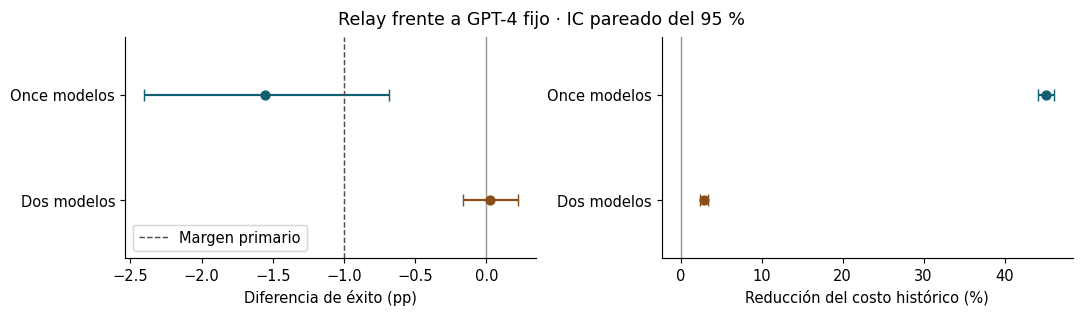

Once modelos · pp de éxito: -1.56 (IC 95 % -2.40 a -0.68).
Once modelos · % de ahorro: 45.13 (IC 95 % 44.16 a 46.12).
Dos modelos · pp de éxito: 0.03 (IC 95 % -0.16 a 0.22).
Dos modelos · % de ahorro: 2.85 (IC 95 % 2.38 a 3.39).
Sensibilidad por 86 grupos: -4.83 a 1.08 pp.
Menor costo demostrado: True
Calidad dentro del margen demostrada: False


In [16]:
from routerbench.final_evaluation import cluster_bootstrap

n_replicas = protocolo["paired_uncertainty"]["replicates"]
referencia = premium_fijo["rows"]
comparaciones = {}
for nombre, evaluado, archivado in [
    ("Once modelos", evaluacion_11, final["policies"]["relay_primary"]["comparison_vs_fixed"]),
    ("Dos modelos", evaluacion_par, informe_par["comparisons"]["relay_common_pair_vs_fixed_strong"])
]:
    contraste = paired_bootstrap(evaluado["rows"], referencia, replicates=n_replicas, seed=SEED)
    comparaciones[nombre] = contraste
    for medida in ["success_rate_delta_95ci", "relative_call_cost_saving_95ci", "cost_per_1000_delta_95ci"]:
        np.testing.assert_allclose(contraste[medida], archivado[medida])
principal = comparaciones["Once modelos"]
margen = protocolo["selection"]["quality_loss_margin"]
por_grupo = cluster_bootstrap(evaluacion_11["rows"], referencia, rows.loc[prueba, "eval_name"],
                              replicates=n_replicas, seed=SEED)
np.testing.assert_allclose(por_grupo["success_rate_delta_95ci"],
                           final["policies"]["relay_primary"]["cluster_sensitivity"]["success_rate_delta_95ci"])

fig, ejes = plt.subplots(1, 2, figsize=(10.2, 2.9), layout="constrained")
for ax, medida, titulo in zip(ejes, ["success_rate_delta", "relative_call_cost_saving"],
                              ["Diferencia de éxito (pp)", "Reducción del costo histórico (%)"]):
    ax.axvline(0, color="0.6", lw=1)
    for y, (nombre, contraste) in enumerate(comparaciones.items()):
        centro = 100 * contraste[medida]
        bajo, alto = np.array(contraste[medida + "_95ci"]) * 100
        ax.errorbar(centro, y, xerr=[[centro-bajo], [alto-centro]], fmt="o",
                    color=["#146073", "#8A4D18"][y], capsize=4)
    ax.set(yticks=[0, 1], yticklabels=list(comparaciones), ylim=(1.55, -0.55), xlabel=titulo)
ejes[0].axvline(-100 * margen, color="0.3", ls="--", lw=1, label="Margen primario")
ejes[0].legend(loc="lower left")
fig.suptitle("Relay frente a GPT-4 fijo · IC pareado del 95 %")
plt.show()

for nombre, contraste in comparaciones.items():
    for medida, unidad in [("success_rate_delta", "pp de éxito"), ("relative_call_cost_saving", "% de ahorro")]:
        bajo, alto = 100 * np.array(contraste[medida + "_95ci"])
        print(f"{nombre} · {unidad}: {100*contraste[medida]:.2f} (IC 95 % {bajo:.2f} a {alto:.2f}).")
li_grupo, ls_grupo = 100 * np.array(por_grupo["success_rate_delta_95ci"])
print(f"Sensibilidad por {por_grupo['groups']} grupos: {li_grupo:.2f} a {ls_grupo:.2f} pp.")
print("Menor costo demostrado:", principal["cost_per_1000_delta_95ci"][1] < 0)
print("Calidad dentro del margen demostrada:", principal["success_rate_delta_95ci"][0] > -margen)

### ¿A quién beneficia y a quién perjudica el cambio?

Una diferencia neta puede ocultar muchos casos en direcciones opuestas. Cruzamos, consulta por consulta, el acierto de GPT-4 y el de la política principal. La diagonal corresponde a desenlaces conservados; las otras dos celdas explican la pérdida neta.

In [17]:
ambos = pd.crosstab(
    referencia["success"].map({False:"GPT-4 falla", True:"GPT-4 acierta"}),
    evaluacion_11["rows"]["success"].map({False:"Relay falla", True:"Relay acierta"})
).rename_axis(index="Referencia", columns="Selección de Relay")
display(ambos)
cambios_favor = ambos.loc["GPT-4 falla", "Relay acierta"]
cambios_contra = ambos.loc["GPT-4 acierta", "Relay falla"]
assert cambios_favor - cambios_contra == evaluacion_11["metrics"]["n_successes"] - premium_fijo["metrics"]["n_successes"]
print(f"Solo Relay acertó en {cambios_favor} consultas y solo GPT-4 en {cambios_contra}. "
      f"Saldo: {cambios_favor-cambios_contra} aciertos en {len(prueba):,} consultas.")

Selección de Relay,Relay acierta,Relay falla
Referencia,,
GPT-4 acierta,5183,575
GPT-4 falla,461,1105


Solo Relay acertó en 461 consultas y solo GPT-4 en 575. Saldo: -114 aciertos en 7,324 consultas.


### ¿Por qué BERT ahorró más usando Mixtral menos veces?

BERT envió **282** consultas a Mixtral y Relay **299**. En las **176** donde solo BERT eligió Mixtral, sus llamadas costaron **0,748 USD menos** en conjunto y obtuvo **29 aciertos menos** que Relay. En las **193** donde solo Relay eligió Mixtral, Relay ahorró **0,260 USD** y obtuvo **15 aciertos menos** que BERT. En otras **6.955** consultas coincidieron. El costo histórico varía por consulta y modelo. Al sumar ambas diferencias, BERT ahorró **4,91 %** frente a GPT-4 fijo y Relay **2,85 %**. Relay consiguió **14 aciertos netos más** que BERT en 7.324 consultas. El IC pareado del 95 % de la diferencia de éxito (−0,01 a +0,40 puntos porcentuales) incluye cero.

La celda reconstruye los cuatro grupos cuando están disponibles las dos tablas por consulta. Un clon limpio puede leer el [agregado de cuatro filas](../reports/routellm-bert-secondary-v1/route_overlap.json) y comprobar sus totales contra el manifiesto publicado. Los costos de la tabla son sumas en USD por grupo.

In [18]:
from routerbench.data import sha256_file

def agrupar_decisiones_par(ruta, huellas):
    """Agrupa las decisiones de Relay y BERT sobre las mismas consultas verificadas."""
    observados = []
    for politica, archivo in (("relay", "relay_common_pair_observed_results.parquet"),
                               ("bert", "routellm_bert_observed_results.parquet")):
        assert sha256_file(ruta / archivo) == huellas[archivo]
        datos = pd.read_parquet(ruta / archivo, columns=["selected_model", "success", "cost"])
        assert datos.index.is_unique and datos.notna().all().all()
        observados.append(datos.add_prefix(politica + "_"))
    relay, bert = observados
    assert relay.index.equals(bert.index)
    unidos = relay.join(bert, validate="one_to_one")
    return unidos.groupby(["relay_selected_model", "bert_selected_model"]).agg(
        n=("relay_success", "size"), relay_successes=("relay_success", "sum"),
        bert_successes=("bert_success", "sum"), relay_total_usd=("relay_cost", "sum"),
        bert_total_usd=("bert_cost", "sum")
    ).round(10).reset_index()

ruta_par = "reports/routellm-bert-secondary-v1"
detalle_par = read_json(f"{ruta_par}/route_overlap.json")
manifiesto_par = read_json(detalle_par["source"])
huellas_par = detalle_par["files_sha256"]
assert all(valor == manifiesto_par["files_sha256"][archivo] for archivo, valor in huellas_par.items())
grupos_par = pd.DataFrame(detalle_par["groups"])
assert len(grupos_par) == 4 and not grupos_par.iloc[:, :2].duplicated().any()
if all((ROOT / ruta_par / archivo).is_file() for archivo in huellas_par):
    recalculo = agrupar_decisiones_par(ROOT / ruta_par, huellas_par)
    pd.testing.assert_frame_equal(recalculo, grupos_par, check_dtype=False)
    print("Cuatro grupos reconstruidos desde las decisiones individuales verificadas.")
else:
    print("Cuatro grupos cargados desde el agregado público.")

# Las dos rutas de ejecución comprueban los mismos totales oficiales.
for politica, clave in (("relay", "relay_common_pair"), ("bert", "routellm_bert")):
    metrica = manifiesto_par["metrics"][clave]
    assert grupos_par["n"].sum() == metrica["n_prompts"]
    assert grupos_par[f"{politica}_successes"].sum() == metrica["n_successes"]
    assert np.isclose(grupos_par[f"{politica}_total_usd"].sum(), metrica["total_cost"], atol=1e-9, rtol=0)

tabla_par = grupos_par.copy()
tabla_par.columns = ["Elección Relay", "Elección BERT", "Consultas", "Aciertos Relay",
                     "Aciertos BERT", "USD Relay", "USD BERT"]
nombres_par = {"gpt-4-1106-preview": "GPT-4", "mistralai/mixtral-8x7b-chat": "Mixtral"}
for columna in ["Elección Relay", "Elección BERT"]:
    tabla_par[columna] = tabla_par[columna].map(nombres_par)
display(tabla_par.round({"USD Relay": 6, "USD BERT": 6}))

Cuatro grupos reconstruidos desde las decisiones individuales verificadas.


,Elección Relay,Elección BERT,Consultas,Aciertos Relay,Aciertos BERT,USD Relay,USD BERT
0,GPT-4,GPT-4,6849,5389,5389,22.163240,22.163240
1,GPT-4,Mixtral,176,134,105,0.783440,0.035548
2,Mixtral,GPT-4,193,154,169,0.012172,0.272640
3,Mixtral,Mixtral,106,83,83,0.017900,0.017900


## Conclusiones y límites

**P1 · Predicción del nivel.** La estructura aporta información. El bosque obtuvo F1 macro de 0,4445 en prueba, frente a 0,3831 para longitud y 0,2323 para mayoría. Sin embargo, solo detectó 29 de las 320 consultas premium. Si el objetivo operativo fuera detectar el nivel caro, habría que elegir la métrica con esa prioridad antes de probar el modelo en otra muestra.

**P2 · Señales del texto.** La proporción de mayúsculas y el número de palabras fueron las señales más estables del bosque para reconocer premium. Pueden reflejar el formato de las tareas. El experimento no midió qué pasa al reescribir un prompt ni qué nivel de esfuerzo de razonamiento necesita un modelo.

**P3 · Consecuencias del enrutamiento.** Elegir un representante por nivel ahorró 94,98 % con una pérdida de 23,55 pp de éxito. La política directa entre once candidatos registró una pérdida de 1,56 pp y ahorró 45,13 %. La evidencia sostiene menor costo histórico. El IC admite perder desde unos 7 hasta unos 24 aciertos por cada mil consultas; el límite prefijado era 10. Por eso el objetivo conjunto de ahorro con calidad dentro del margen quedó sin demostrar.

**Decisión secundaria.** Con GPT-4 y Mixtral, Relay obtuvo dos aciertos netos más que GPT-4 fijo con 2,85 % de ahorro. El intervalo de la diferencia de calidad incluye el empate. BERT ahorró 4,91 % frente a GPT-4, y Relay tuvo 14 aciertos más que BERT en la muestra. Son políticas con distintos puntos de operación. Para un servicio que tolere como máximo diez pérdidas por mil, la política binaria sería una candidata para una prueba nueva; el resultado secundario no sustituye la evaluación primaria.

**Alcance.** Un puntaje de 0,75 no representa necesariamente la misma utilidad en tareas diferentes. Un mismo tipo de evaluación puede aparecer en entrenamiento y en prueba. De hecho, al remuestrear por nombre de evaluación, la incertidumbre de la diferencia principal de éxito se amplía hasta incluir cero. Las tarifas, los modelos y las respuestas son históricos, y el costo excluye selector, entrenamiento y reintentos. La evaluación de la aplicación con usuarios, modelos actuales y costo total requeriría fijar el criterio antes de recoger consultas nuevas.

[Datos de RouterBench](https://doi.org/10.57967/hf/1996) · [Artículo de RouterBench](https://arxiv.org/abs/2403.12031v2) · [Artículo de RouteLLM](https://arxiv.org/abs/2406.18665v4) · [Manifiestos de Relay](../reports/final/summary.json)

## Declaración de uso de IA generativa

Se utilizó OpenAI Codex para organizar este cuaderno a partir del repositorio de Relay, redactar y revisar el código y las explicaciones, preparar las figuras, ejecutar las celdas y cotejar sus resultados con los manifiestos del estudio. Los datos proceden de RouterBench. Las cifras de los modelos ajustados aquí se calculan en las celdas de evaluación. Para las variantes semánticas y BERT se indica dónde se realizó la ejecución externa y qué resultados se recuperaron.